In [4]:
import pandas as pd
from pandas import to_datetime

In [5]:
train = pd.read_csv("train.csv",low_memory=False)
store = pd.read_csv("store.csv")

In [6]:
print("Train shape:",train.shape)
print("Store shape:",store.shape)


Train shape: (1017209, 9)
Store shape: (1115, 10)


In [7]:
train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB


In [8]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


In [9]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [10]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [11]:
train.duplicated().sum()

np.int64(0)

In [12]:
train.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [13]:
train['Store'].nunique()

1115

In [14]:
train['Date'] = to_datetime(train['Date'])

In [15]:
print("Start date:", train['Date'].min())
print("End date:", train['Date'].max())

Start date: 2013-01-01 00:00:00
End date: 2015-07-31 00:00:00


In [16]:
daily_sales = train.groupby('Date')['Sales'].sum()
daily_sales.head()

Date
2013-01-01      97235
2013-01-02    6949829
2013-01-03    6347820
2013-01-04    6638954
2013-01-05    5951593
Name: Sales, dtype: int64

In [17]:
daily_sales = train.groupby('Date')['Sales'].sum()
daily_sales.head()

Date
2013-01-01      97235
2013-01-02    6949829
2013-01-03    6347820
2013-01-04    6638954
2013-01-05    5951593
Name: Sales, dtype: int64

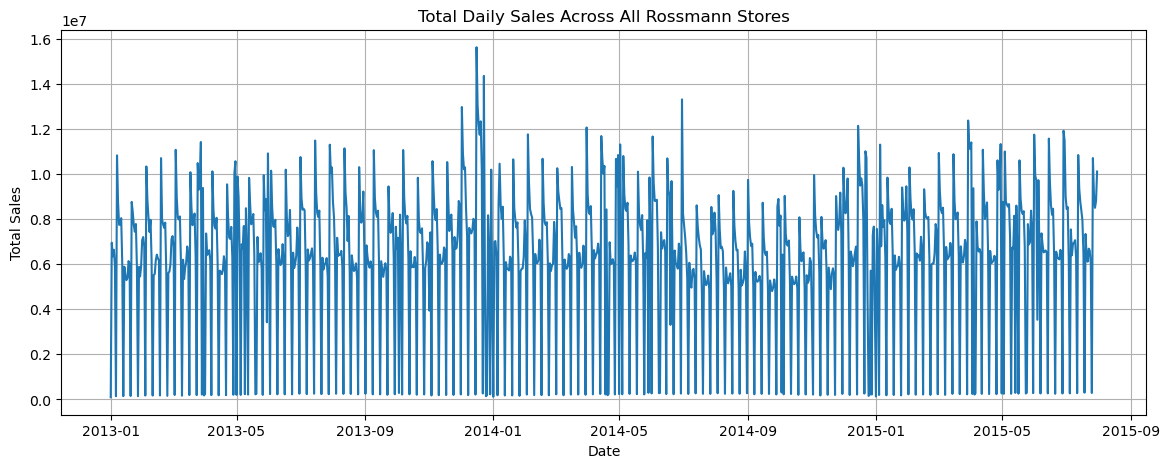

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)

plt.title('Total Daily Sales Across All Rossmann Stores')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid(True)

plt.show()

In [19]:

avg_sales_by_day = train.groupby('DayOfWeek')['Sales'].mean()

print(avg_sales_by_day)


DayOfWeek
1    7809.044510
2    7005.244467
3    6555.884138
4    6247.575913
5    6723.274305
6    5847.562599
7     204.183189
Name: Sales, dtype: float64


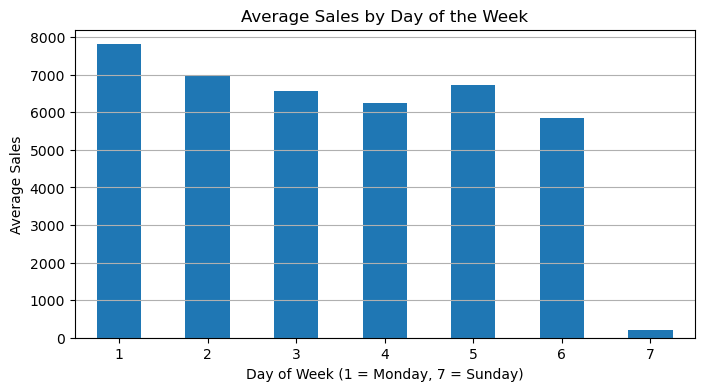

In [20]:

avg_sales_by_day.plot(kind='bar', figsize=(8, 4))

plt.title('Average Sales by Day of the Week')
plt.xlabel('Day of Week (1 = Monday, 7 = Sunday)')
plt.ylabel('Average Sales')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()


In [21]:

promo_sales = train.groupby('Promo')['Sales'].mean()

print(promo_sales)


Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64


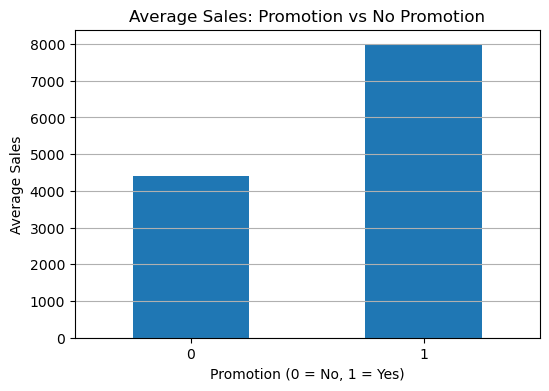

In [22]:

promo_sales.plot(kind='bar', figsize=(6, 4))

plt.title('Average Sales: Promotion vs No Promotion')
plt.xlabel('Promotion (0 = No, 1 = Yes)')
plt.ylabel('Average Sales')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()


In [23]:

promo_sales = train.groupby('Promo')['Sales'].mean()

print(promo_sales)


Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64


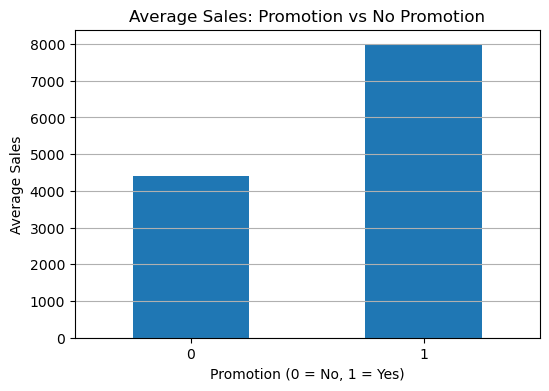

In [24]:

promo_sales.plot(kind='bar', figsize=(6, 4))

plt.title('Average Sales: Promotion vs No Promotion')
plt.xlabel('Promotion (0 = No, 1 = Yes)')
plt.ylabel('Average Sales')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()


In [25]:

store_sales = train.groupby('Store')['Sales'].mean()

top_10_stores = store_sales.sort_values(ascending=False).head(10)

print(top_10_stores)


Store
262     20718.515924
817     18108.139066
562     17969.556263
1114    17200.196391
251     15814.087049
842     15242.114776
513     15129.942675
788     14949.194268
733     14933.288747
383     14320.466030
Name: Sales, dtype: float64


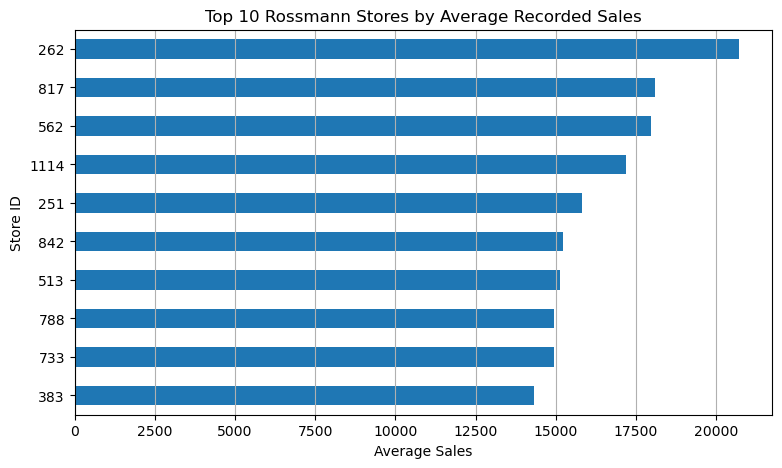

In [26]:

top_10_stores.sort_values().plot(kind='barh', figsize=(9, 5))

plt.title('Top 10 Rossmann Stores by Average Recorded Sales')
plt.xlabel('Average Sales')
plt.ylabel('Store ID')
plt.grid(axis='x')
plt.show()


In [27]:

# Combine daily sales with store information
df = train.merge(
    store,
    on='Store',
    how='left',
    validate='many_to_one'
)

# Sort chronologically within each store
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

print("Combined dataset shape:", df.shape)
print("Date range:", df['Date'].min(), "to", df['Date'].max())
print("Missing values:", df.isnull().sum().sum())

df.head()


Combined dataset shape: (1017209, 18)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00
Missing values: 2173431


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,2,2013-01-01,0,0,0,0,a,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,1,3,2013-01-02,5530,668,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
2,1,4,2013-01-03,4327,578,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
3,1,5,2013-01-04,4486,619,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
4,1,6,2013-01-05,4997,635,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN


In [28]:

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Ensure dates are datetime and records are ordered
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

# Define the periods
train_end = pd.Timestamp('2015-05-31')
validation_start = pd.Timestamp('2015-06-01')
validation_end = pd.Timestamp('2015-07-31')

train_df = df[df['Date'] <= train_end].copy()

valid_df = df[
    (df['Date'] >= validation_start) &
    (df['Date'] <= validation_end)
].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(valid_df))
print("Training end:", train_df['Date'].max())
print("Validation period:", valid_df['Date'].min(), "to", valid_df['Date'].max())


Training rows: 949194
Validation rows: 68015
Training end: 2015-05-31 00:00:00
Validation period: 2015-06-01 00:00:00 to 2015-07-31 00:00:00


In [29]:

# Previous week's sales for the same store
df['Baseline_Prediction'] = (
    df.groupby('Store')['Sales'].shift(7)
)

# Select validation rows and remove rows without a baseline
baseline_valid = df[
    (df['Date'] >= validation_start) &
    (df['Date'] <= validation_end)
].copy()

baseline_valid = baseline_valid.dropna(subset=['Baseline_Prediction'])

# Evaluate the baseline
mae = mean_absolute_error(
    baseline_valid['Sales'],
    baseline_valid['Baseline_Prediction']
)

rmse = np.sqrt(mean_squared_error(
    baseline_valid['Sales'],
    baseline_valid['Baseline_Prediction']
))

print(f"Baseline MAE:  {mae:.2f}")
print(f"Baseline RMSE: {rmse:.2f}")


Baseline MAE:  2123.37
Baseline RMSE: 3047.47


In [30]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 5.4 MB/s eta 0:00:09
   - -------------------------------------- 1.3/48.9 MB 4.5 MB/s eta 0:00:11
   - -------------------------------------- 1.8/48.9 MB 3.0 MB/s eta 0:00:16
   - -------------------------------------- 1.8/48.9 MB 3.0 MB/s eta 0:00:16
   - -------------------------------------- 2.1/48.9 MB 2.0 MB/s eta 0:00:24
   -- ------------------------------------- 2.6/48.9 MB 2.1 MB/s eta 0:00:23
   -- ------------------------------------- 3.1/48.9 MB 2.2 MB/s eta 0:00:22
   --- ------------------------------------ 3.9/48.9 MB 2.3 MB/s eta 0:00:20
   --- ------------------------------------ 4.5/48.9 MB 2.3 MB/s eta 0:00:20
   --- ------------------------------------ 4.7/48.9 MB 2.2 MB/s eta 0:00:20
   ---- ----------------------------------- 5.8/48.9 MB 2.5 MB/s eta 0:00:18
   ----- ---------------------------------- 6.3/48.9 MB 2.5 MB/s eta 0:00:18
   ---

In [31]:

import numpy as np
import pandas as pd

# Work with a copy of the combined dataset
model_df = df.copy()
model_df['Date'] = pd.to_datetime(model_df['Date'])

# Calendar features
model_df['Year'] = model_df['Date'].dt.year
model_df['Month'] = model_df['Date'].dt.month
model_df['Day'] = model_df['Date'].dt.day
model_df['WeekOfYear'] = (
    model_df['Date'].dt.isocalendar().week.astype(int)
)

# Encode the holiday column consistently
model_df['StateHoliday'] = (
    model_df['StateHoliday'].astype(str)
)

# Sort before creating historical features
model_df = model_df.sort_values(
    ['Store', 'Date']
).reset_index(drop=True)

# Previous-week sales
model_df['Lag_7'] = (
    model_df.groupby('Store')['Sales'].shift(7)
)

# Rolling average of the previous 7 days,
# excluding the current day's sales
model_df['RollingMean_7'] = (
    model_df.groupby('Store')['Sales']
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

print("Prepared dataset shape:", model_df.shape)
print(model_df[['Date', 'Store', 'Sales', 'Lag_7', 'RollingMean_7']].head(10))


Prepared dataset shape: (1017209, 25)
        Date  Store  Sales   Lag_7  RollingMean_7
0 2013-01-01      1      0     NaN            NaN
1 2013-01-02      1   5530     NaN            NaN
2 2013-01-03      1   4327     NaN            NaN
3 2013-01-04      1   4486     NaN            NaN
4 2013-01-05      1   4997     NaN            NaN
5 2013-01-06      1      0     NaN            NaN
6 2013-01-07      1   7176     NaN            NaN
7 2013-01-08      1   5580     0.0    3788.000000
8 2013-01-09      1   5471  5530.0    4585.142857
9 2013-01-10      1   4892  4327.0    4576.714286


In [32]:
print("Dataset shape:", model_df.shape)
print("Date range:", model_df['Date'].min(), "to", model_df['Date'].max())

print("\nMissing values in important columns:")
print(model_df[
    ['Sales', 'Store', 'Open', 'Promo', 'Lag_7', 'RollingMean_7']
].isnull().sum())

print("\nColumns available:")
print(model_df.columns.tolist())

Dataset shape: (1017209, 25)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00

Missing values in important columns:
Sales               0
Store               0
Open                0
Promo               0
Lag_7            7805
RollingMean_7    7805
dtype: int64

Columns available:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'Baseline_Prediction', 'Year', 'Month', 'Day', 'WeekOfYear', 'Lag_7', 'RollingMean_7']


In [33]:
# Training and validation date ranges
train_data = model_df[model_df['Date'] <= '2015-05-31'].copy()

valid_data = model_df[
    (model_df['Date'] >= '2015-06-01') &
    (model_df['Date'] <= '2015-07-31')
].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(valid_data))

print("Training ends:", train_data['Date'].max())
print("Validation starts:", valid_data['Date'].min())
print("Validation ends:", valid_data['Date'].max())

Training rows: 949194
Validation rows: 68015
Training ends: 2015-05-31 00:00:00
Validation starts: 2015-06-01 00:00:00
Validation ends: 2015-07-31 00:00:00


In [34]:
feature_cols = [
    'Store',
    'DayOfWeek',
    'Open',
    'Promo',
    'StateHoliday',
    'SchoolHoliday',
    'StoreType',
    'Assortment',
    'CompetitionDistance',
    'Promo2',
    'Year',
    'Month',
    'Day',
    'WeekOfYear',
    'Lag_7',
    'RollingMean_7'
]

target_col = 'Sales'

X_train = train_data[feature_cols].copy()
y_train = train_data[target_col].copy()

X_valid = valid_data[feature_cols].copy()
y_valid = valid_data[target_col].copy()

print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)

Training features: (949194, 16)
Validation features: (68015, 16)


In [35]:
import pandas as pd
import numpy as np

# Copy the feature datasets
X_train_clean = X_train.copy()
X_valid_clean = X_valid.copy()

# Identify categorical columns
categorical_cols = [
    'StateHoliday',
    'StoreType',
    'Assortment'
]

# Convert categorical columns to consistent strings
for col in categorical_cols:
    X_train_clean[col] = X_train_clean[col].fillna('Unknown').astype(str)
    X_valid_clean[col] = X_valid_clean[col].fillna('Unknown').astype(str)

# One-hot encode categories
X_train_clean = pd.get_dummies(X_train_clean, columns=categorical_cols)
X_valid_clean = pd.get_dummies(X_valid_clean, columns=categorical_cols)

# Align validation columns with training columns
X_valid_clean = X_valid_clean.reindex(
    columns=X_train_clean.columns,
    fill_value=0
)

# Replace infinite values and handle missing numeric values
X_train_clean = X_train_clean.replace([np.inf, -np.inf], np.nan)
X_valid_clean = X_valid_clean.replace([np.inf, -np.inf], np.nan)

X_train_clean = X_train_clean.fillna(0)
X_valid_clean = X_valid_clean.fillna(0)

print("Clean training features:", X_train_clean.shape)
print("Clean validation features:", X_valid_clean.shape)
print("Any missing values in training:", X_train_clean.isnull().sum().sum())
print("Any missing values in validation:", X_valid_clean.isnull().sum().sum())

Clean training features: (949194, 24)
Clean validation features: (68015, 24)
Any missing values in training: 0
Any missing values in validation: 0


In [36]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Train only on days when the store was open
train_mask = (
    (train_data['Open'] == 1) &
    (train_data['Sales'] > 0)
)

# Evaluate only on open validation days
valid_mask = (
    (valid_data['Open'] == 1) &
    (valid_data['Sales'] > 0)
)

X_train_model = X_train_clean.loc[train_mask]
y_train_model = y_train.loc[train_mask]

X_valid_model = X_valid_clean.loc[valid_mask]
y_valid_model = y_valid.loc[valid_mask]

# Create the XGBoost model
xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    eval_metric='mae',
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train_model, y_train_model)

# Predict
y_pred = xgb_model.predict(X_valid_model)

# Evaluate
mae = mean_absolute_error(y_valid_model, y_pred)
rmse = np.sqrt(mean_squared_error(y_valid_model, y_pred))

print(f"Validation MAE:  {mae:.2f}")
print(f"Validation RMSE: {rmse:.2f}")

Validation MAE:  761.23
Validation RMSE: 1054.59


In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create a lookup table of historical sales
sales_lookup = model_df[['Store', 'Date', 'Sales']].copy()

# Match each date with the same store's sales 7 calendar days earlier
baseline_data = valid_data[['Store', 'Date', 'Sales', 'Open']].copy()
baseline_data['PreviousWeekDate'] = (
    baseline_data['Date'] - pd.Timedelta(days=7)
)

baseline_data = baseline_data.merge(
    sales_lookup.rename(columns={
        'Date': 'PreviousWeekDate',
        'Sales': 'Baseline_Prediction'
    }),
    on=['Store', 'PreviousWeekDate'],
    how='left',
    validate='many_to_one'
)

# Evaluate on the same open validation rows used for XGBoost
baseline_mask = (
    (baseline_data['Open'] == 1) &
    (baseline_data['Sales'] > 0) &
    baseline_data['Baseline_Prediction'].notna()
)

baseline_actual = baseline_data.loc[baseline_mask, 'Sales']
baseline_pred = baseline_data.loc[baseline_mask, 'Baseline_Prediction']

baseline_mae = mean_absolute_error(baseline_actual, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(baseline_actual, baseline_pred)
)

print(f"Baseline MAE:  {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Baseline evaluation rows: {len(baseline_actual)}")
print(f"XGBoost MAE: {mae:.2f}")
print(f"XGBoost RMSE: {rmse:.2f}")

Baseline MAE:  2391.60
Baseline RMSE: 3208.40
Baseline evaluation rows: 58611
XGBoost MAE: 761.23
XGBoost RMSE: 1054.59


In [38]:
# Compare XGBoost against the seasonal baseline

print("MODEL PERFORMANCE COMPARISON")
print("-" * 40)
print(f"XGBoost MAE:       {mae:.2f}")
print(f"Seasonal MAE:      {baseline_mae:.2f}")
print(f"XGBoost RMSE:      {rmse:.2f}")
print(f"Seasonal RMSE:     {baseline_rmse:.2f}")

# Percentage improvement in MAE
if baseline_mae != 0:
    improvement = (
        (baseline_mae - mae) / baseline_mae
    ) * 100

    print(f"\nMAE improvement: {improvement:.2f}%")

    if improvement > 0:
        print("XGBoost performs better on MAE.")
    elif improvement < 0:
        print("The seasonal baseline performs better on MAE.")
    else:
        print("Both models have the same MAE.")

MODEL PERFORMANCE COMPARISON
----------------------------------------
XGBoost MAE:       761.23
Seasonal MAE:      2391.60
XGBoost RMSE:      1054.59
Seasonal RMSE:     3208.40

MAE improvement: 68.17%
XGBoost performs better on MAE.


           Feature  Importance
3            Promo    0.314092
12   RollingMean_7    0.274464
11           Lag_7    0.108407
1        DayOfWeek    0.070603
9              Day    0.033257
22    Assortment_b    0.026858
10      WeekOfYear    0.023892
8            Month    0.017724
18     StoreType_b    0.015390
7             Year    0.013050
13  StateHoliday_0    0.012589
6           Promo2    0.011325
17     StoreType_a    0.010885
14  StateHoliday_a    0.010454
4    SchoolHoliday    0.010327


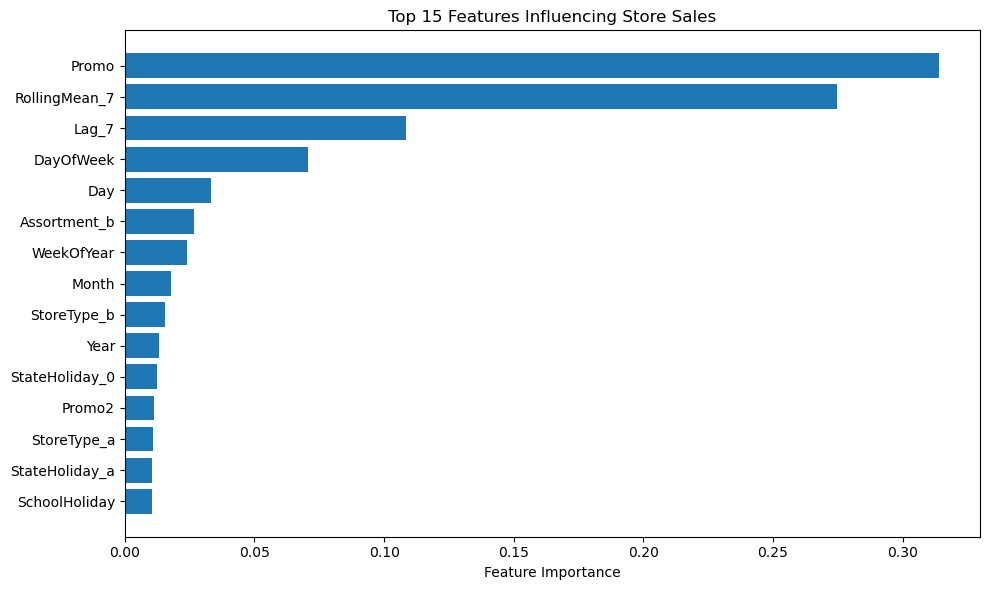

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from the trained model
importance_df = pd.DataFrame({
    'Feature': X_train_model.columns,
    'Importance': xgb_model.feature_importances_
})

# Sort and select top 15
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).head(15)

print(importance_df)

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df['Feature'][::-1],
    importance_df['Importance'][::-1]
)
plt.xlabel("Feature Importance")
plt.title("Top 15 Features Influencing Store Sales")
plt.tight_layout()
plt.show()

In [40]:
# Create a results table for XGBoost predictions
results = valid_data.loc[valid_mask, ['Date', 'Store', 'Sales', 'Promo', 'DayOfWeek']].copy()

results['Actual_Sales'] = y_valid_model.values
results['Predicted_Sales'] = y_pred
results['Absolute_Error'] = abs(
    results['Actual_Sales'] - results['Predicted_Sales']
)

print("Mean Absolute Error:", round(results['Absolute_Error'].mean(), 2))

print("\nLargest prediction errors:")
print(
    results.sort_values('Absolute_Error', ascending=False)
    .head(10)
    [['Date', 'Store', 'Actual_Sales', 'Predicted_Sales', 'Absolute_Error']]
)

Mean Absolute Error: 761.23

Largest prediction errors:
             Date  Store  Actual_Sales  Predicted_Sales  Absolute_Error
828270 2015-06-22    909         41551     11939.017578    29611.982422
265095 2015-06-29    292         29161      8947.378906    20213.621094
798854 2015-07-06    876         27330     10573.342773    16756.657227
828271 2015-06-23    909         30038     14046.114258    15991.885742
828298 2015-07-20    909         23081      7482.140625    15598.859375
828277 2015-06-29    909          6125     20292.314453    14167.314453
828268 2015-06-20    909         22882      9801.560547    13080.439453
798855 2015-07-07    876         23927     12074.322266    11852.677734
265096 2015-06-30    292         23584     12287.823242    11296.176758
828275 2015-06-27    909          6990     17753.361328    10763.361328


Average absolute error by promotion status:
Promo
0    677.244262
1    858.462474
Name: Absolute_Error, dtype: float64


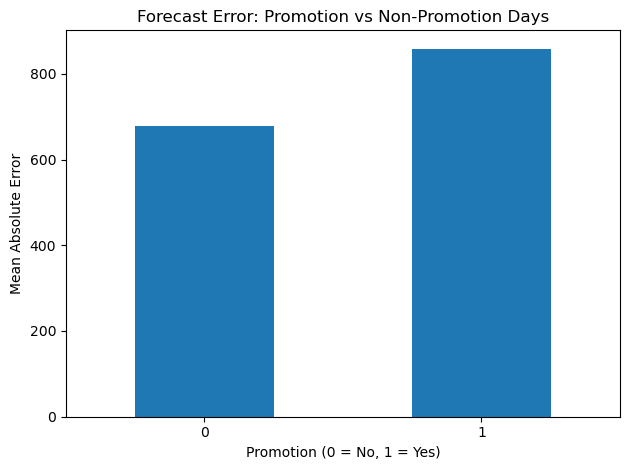

In [41]:
promo_error = results.groupby('Promo')['Absolute_Error'].mean()

print("Average absolute error by promotion status:")
print(promo_error)

promo_error.plot(
    kind='bar',
    xlabel='Promotion (0 = No, 1 = Yes)',
    ylabel='Mean Absolute Error',
    title='Forecast Error: Promotion vs Non-Promotion Days',
    rot=0
)

import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()

In [42]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

configs = [
    {"name": "Model 1 - Current", "max_depth": 8, "learning_rate": 0.05,
     "n_estimators": 500},
    {"name": "Model 2 - Shallower", "max_depth": 5, "learning_rate": 0.05,
     "n_estimators": 500},
    {"name": "Model 3 - More Trees", "max_depth": 6, "learning_rate": 0.03,
     "n_estimators": 800}
]

tuning_results = []
tuned_models = {}

for config in configs:
    model = XGBRegressor(
        max_depth=config["max_depth"],
        learning_rate=config["learning_rate"],
        n_estimators=config["n_estimators"],
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        eval_metric="mae",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_model, y_train_model)
    predictions = model.predict(X_valid_model)

    score = mean_absolute_error(y_valid_model, predictions)

    tuning_results.append({
        "Model": config["name"],
        "Max Depth": config["max_depth"],
        "Learning Rate": config["learning_rate"],
        "Trees": config["n_estimators"],
        "Validation MAE": round(score, 2)
    })

    tuned_models[config["name"]] = model

tuning_df = pd.DataFrame(tuning_results).sort_values(
    "Validation MAE"
)

print(tuning_df.to_string(index=False))

               Model  Max Depth  Learning Rate  Trees  Validation MAE
   Model 1 - Current          8           0.05    500          761.23
Model 3 - More Trees          6           0.03    800          767.37
 Model 2 - Shallower          5           0.05    500          768.85


Best model: Model 1 - Current
Validation MAE: 761.23


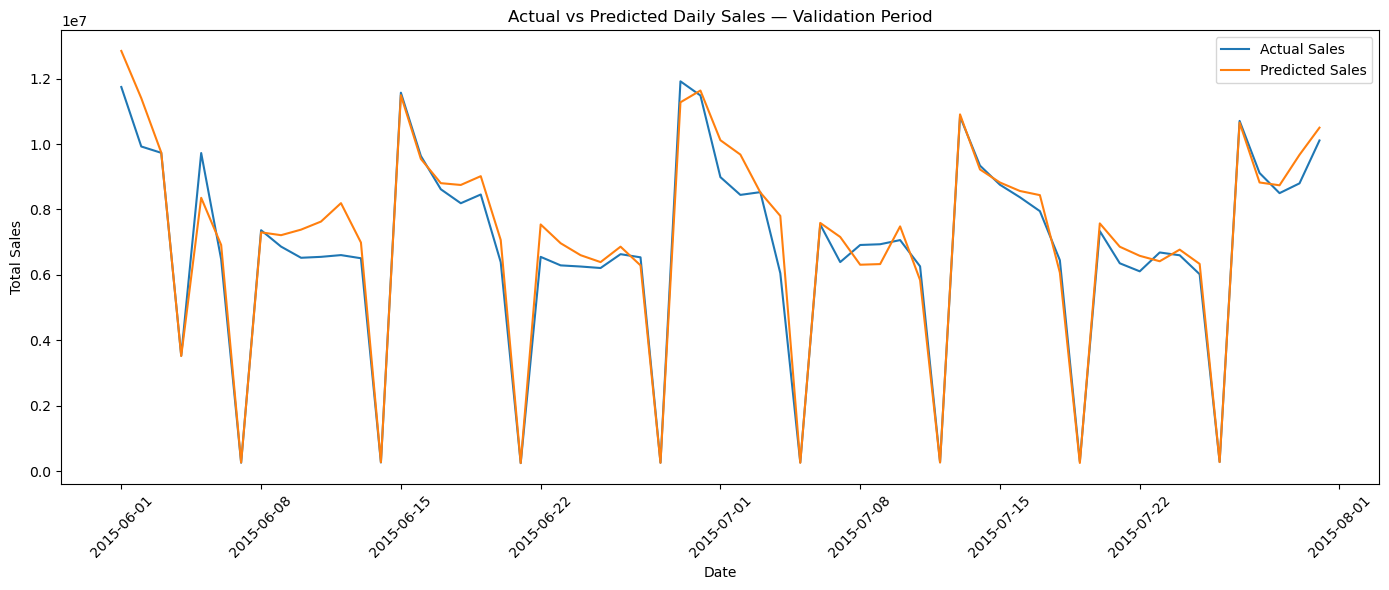

In [43]:
import matplotlib.pyplot as plt
import pandas as pd

# Select the best model from Step 9
best_model_name = tuning_df.iloc[0]["Model"]
best_model = tuned_models[best_model_name]

print("Best model:", best_model_name)
print("Validation MAE:", tuning_df.iloc[0]["Validation MAE"])

# Generate predictions
best_predictions = best_model.predict(X_valid_model)

# Prepare results
plot_data = valid_data.loc[
    valid_mask, ['Date', 'Sales']
].copy()

plot_data['Predicted_Sales'] = best_predictions

# Aggregate sales across stores for each date
daily_comparison = plot_data.groupby('Date')[
    ['Sales', 'Predicted_Sales']
].sum()

# Plot
plt.figure(figsize=(14, 6))
plt.plot(
    daily_comparison.index,
    daily_comparison['Sales'],
    label='Actual Sales'
)
plt.plot(
    daily_comparison.index,
    daily_comparison['Predicted_Sales'],
    label='Predicted Sales'
)

plt.title('Actual vs Predicted Daily Sales — Validation Period')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
# Check date gaps within each store
date_check = model_df.sort_values(['Store', 'Date']).copy()

date_check['Days_Between_Rows'] = (
    date_check.groupby('Store')['Date']
    .diff()
    .dt.days
)

print("Days between consecutive rows:")
print(date_check['Days_Between_Rows'].value_counts().sort_index())

print("\nRows with gaps greater than one day:")
print((date_check['Days_Between_Rows'] > 1).sum())

print("\nLargest date gap in days:")
print(date_check['Days_Between_Rows'].max())

Days between consecutive rows:
Days_Between_Rows
1.0      1015914
185.0        180
Name: count, dtype: int64

Rows with gaps greater than one day:
180

Largest date gap in days:
185.0


In [45]:
# Compare row-based lag against true calendar 7-day lag
lag_check = model_df[['Store', 'Date', 'Sales', 'Lag_7']].copy()
lag_check['PreviousWeekDate'] = (
    lag_check['Date'] - pd.Timedelta(days=7)
)

previous_sales = model_df[['Store', 'Date', 'Sales']].rename(
    columns={
        'Date': 'PreviousWeekDate',
        'Sales': 'Actual_Lag_7'
    }
)

lag_check = lag_check.merge(
    previous_sales,
    on=['Store', 'PreviousWeekDate'],
    how='left',
    validate='many_to_one'
)

comparable = lag_check['Lag_7'].notna() & lag_check['Actual_Lag_7'].notna()

mismatches = (
    lag_check.loc[comparable, 'Lag_7']
    != lag_check.loc[comparable, 'Actual_Lag_7']
)

print("Rows compared:", int(comparable.sum()))
print("Lag mismatches:", int(mismatches.sum()))
print("Rows without a calendar 7-day match:", int(
    lag_check['Actual_Lag_7'].isna().sum()
))

Rows compared: 1008144
Lag mismatches: 0
Rows without a calendar 7-day match: 9065


In [46]:
import pandas as pd

# Sort historical data
model_df = model_df.sort_values(
    ['Store', 'Date']
).reset_index(drop=True)

# Create a lookup for sales exactly 7 calendar days earlier
previous_week = model_df[['Store', 'Date', 'Sales']].copy()
previous_week['Date'] = (
    previous_week['Date'] + pd.Timedelta(days=7)
)
previous_week = previous_week.rename(
    columns={'Sales': 'Lag_7_Calendar'}
)

model_df = model_df.drop(
    columns=['Lag_7', 'RollingMean_7'],
    errors='ignore'
).merge(
    previous_week,
    on=['Store', 'Date'],
    how='left',
    validate='many_to_one'
)

# Build a rolling mean using the previous 7 calendar days only
# This excludes the current day's sales.
sales_history = model_df.set_index('Date').groupby('Store')['Sales']

model_df['RollingMean_7_Calendar'] = (
    model_df.groupby('Store')['Sales']
    .transform(
        lambda s: s.shift(1).rolling(window=7, min_periods=1).mean()
    )
)

# Use the corrected lag feature
model_df['Lag_7'] = model_df['Lag_7_Calendar']
model_df['RollingMean_7'] = model_df['RollingMean_7_Calendar']

print("Corrected lag features created.")
print(
    model_df[
        ['Store', 'Date', 'Sales', 'Lag_7', 'RollingMean_7']
    ].head(10)
)
print("\nMissing Lag_7 values:", model_df['Lag_7'].isna().sum())

Corrected lag features created.
   Store       Date  Sales   Lag_7  RollingMean_7
0      1 2013-01-01      0     NaN            NaN
1      1 2013-01-02   5530     NaN       0.000000
2      1 2013-01-03   4327     NaN    2765.000000
3      1 2013-01-04   4486     NaN    3285.666667
4      1 2013-01-05   4997     NaN    3585.750000
5      1 2013-01-06      0     NaN    3868.000000
6      1 2013-01-07   7176     NaN    3223.333333
7      1 2013-01-08   5580     0.0    3788.000000
8      1 2013-01-09   5471  5530.0    4585.142857
9      1 2013-01-10   4892  4327.0    4576.714286

Missing Lag_7 values: 9065


In [47]:
# Split chronologically
train_data = model_df[
    model_df['Date'] <= '2015-05-31'
].copy()

valid_data = model_df[
    (model_df['Date'] >= '2015-06-01') &
    (model_df['Date'] <= '2015-07-31')
].copy()

# Define predictors — Customers is deliberately excluded
feature_cols = [
    'Store', 'DayOfWeek', 'Open', 'Promo',
    'StateHoliday', 'SchoolHoliday',
    'StoreType', 'Assortment',
    'CompetitionDistance', 'Promo2',
    'Year', 'Month', 'Day', 'WeekOfYear',
    'Lag_7', 'RollingMean_7'
]

X_train = train_data[feature_cols].copy()
y_train = train_data['Sales'].copy()

X_valid = valid_data[feature_cols].copy()
y_valid = valid_data['Sales'].copy()

print("Training data:", X_train.shape)
print("Validation data:", X_valid.shape)
print("Training period:", train_data['Date'].min(), "to", train_data['Date'].max())
print("Validation period:", valid_data['Date'].min(), "to", valid_data['Date'].max())

Training data: (949194, 16)
Validation data: (68015, 16)
Training period: 2013-01-01 00:00:00 to 2015-05-31 00:00:00
Validation period: 2015-06-01 00:00:00 to 2015-07-31 00:00:00


In [48]:
import pandas as pd
import numpy as np

categorical_cols = [
    'StateHoliday', 'StoreType', 'Assortment'
]

for col in categorical_cols:
    X_train[col] = X_train[col].fillna('Unknown').astype(str)
    X_valid[col] = X_valid[col].fillna('Unknown').astype(str)

X_train_clean = pd.get_dummies(
    X_train, columns=categorical_cols
)

X_valid_clean = pd.get_dummies(
    X_valid, columns=categorical_cols
)

X_valid_clean = X_valid_clean.reindex(
    columns=X_train_clean.columns,
    fill_value=0
)

X_train_clean = X_train_clean.replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

X_valid_clean = X_valid_clean.replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

print("Clean training features:", X_train_clean.shape)
print("Clean validation features:", X_valid_clean.shape)

Clean training features: (949194, 24)
Clean validation features: (68015, 24)


In [49]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Train and evaluate on open days with positive sales
train_mask = (
    (train_data['Open'] == 1) &
    (train_data['Sales'] > 0)
)

valid_mask = (
    (valid_data['Open'] == 1) &
    (valid_data['Sales'] > 0)
)

X_train_model = X_train_clean.loc[train_mask]
y_train_model = y_train.loc[train_mask]

X_valid_model = X_valid_clean.loc[valid_mask]
y_valid_model = y_valid.loc[valid_mask]

# Train XGBoost
xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    eval_metric='mae',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_model, y_train_model)

# Predict and evaluate
y_pred = xgb_model.predict(X_valid_model)

mae = mean_absolute_error(y_valid_model, y_pred)
rmse = np.sqrt(mean_squared_error(y_valid_model, y_pred))

print(f"Corrected XGBoost MAE:  {mae:.2f}")
print(f"Corrected XGBoost RMSE: {rmse:.2f}")
print("Training rows:", len(y_train_model))
print("Validation rows:", len(y_valid_model))

Corrected XGBoost MAE:  770.24
Corrected XGBoost RMSE: 1072.10
Training rows: 785727
Validation rows: 58611


In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Use the corrected date-based lag for validation predictions
baseline_actual_data = valid_data.loc[
    valid_mask, ['Store', 'Date', 'Sales', 'Lag_7']
].copy()

# Only compare rows where the previous-week sales are available
baseline_mask = baseline_actual_data['Lag_7'].notna()

baseline_actual = baseline_actual_data.loc[
    baseline_mask, 'Sales'
]
baseline_pred = baseline_actual_data.loc[
    baseline_mask, 'Lag_7'
]

# XGBoost predictions on the exact same rows
xgb_positions = baseline_actual_data.index[baseline_mask]
xgb_predictions = pd.Series(
    y_pred,
    index=valid_data.index[valid_mask]
).loc[xgb_positions]

baseline_mae = mean_absolute_error(
    baseline_actual, baseline_pred
)
baseline_rmse = np.sqrt(
    mean_squared_error(baseline_actual, baseline_pred)
)

xgb_mae_fair = mean_absolute_error(
    baseline_actual, xgb_predictions
)
xgb_rmse_fair = np.sqrt(
    mean_squared_error(baseline_actual, xgb_predictions)
)

improvement = (
    (baseline_mae - xgb_mae_fair) / baseline_mae * 100
    if baseline_mae else 0
)

print(f"Seasonal baseline MAE: {baseline_mae:.2f}")
print(f"XGBoost MAE:           {xgb_mae_fair:.2f}")
print(f"Seasonal baseline RMSE:{baseline_rmse:.2f}")
print(f"XGBoost RMSE:          {xgb_rmse_fair:.2f}")
print(f"MAE improvement:       {improvement:.2f}%")
print(f"Rows compared:         {len(baseline_actual)}")

Seasonal baseline MAE: 2391.60
XGBoost MAE:           770.24
Seasonal baseline RMSE:3208.40
XGBoost RMSE:          1072.10
MAE improvement:       67.79%
Rows compared:         58611


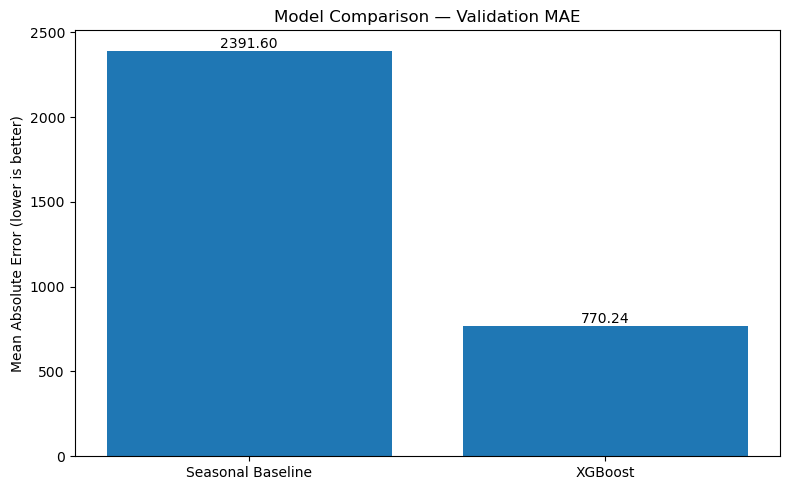

In [51]:
import matplotlib.pyplot as plt

model_names = ['Seasonal Baseline', 'XGBoost']
mae_scores = [baseline_mae, xgb_mae_fair]

plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, mae_scores)

plt.title('Model Comparison — Validation MAE')
plt.ylabel('Mean Absolute Error (lower is better)')

for bar, score in zip(bars, mae_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{score:.2f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Top 15 Important Features:
       Feature  Importance
         Promo    0.306110
 RollingMean_7    0.280937
         Lag_7    0.108445
     DayOfWeek    0.071718
           Day    0.033476
  Assortment_b    0.025753
    WeekOfYear    0.023579
         Month    0.017871
   StoreType_b    0.016425
StateHoliday_0    0.013440
          Year    0.013161
        Promo2    0.011466
 SchoolHoliday    0.011223
   StoreType_a    0.010938
StateHoliday_a    0.010461


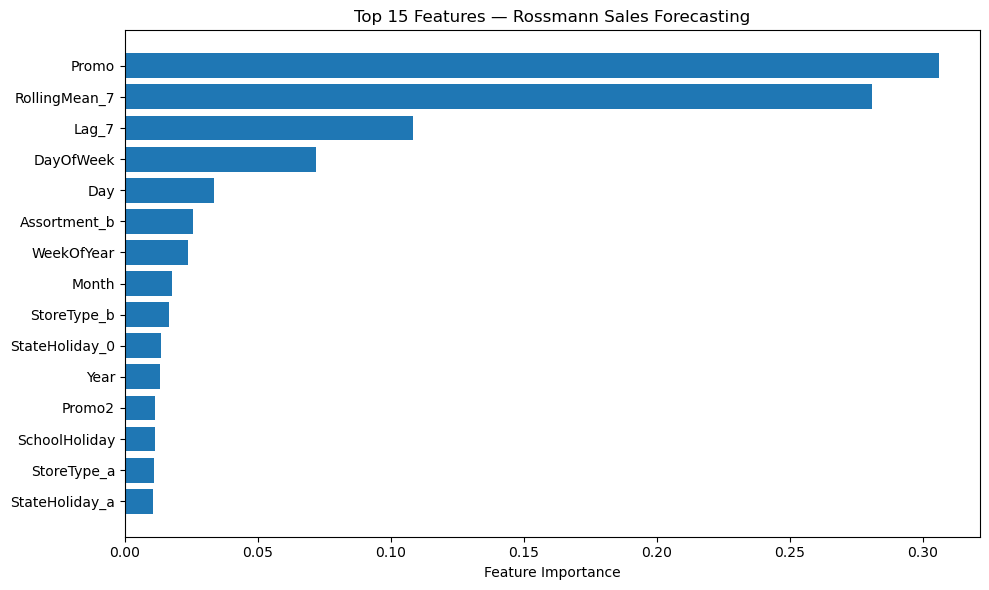

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from the corrected model
importance_df = pd.DataFrame({
    'Feature': X_train_model.columns,
    'Importance': xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features:")
print(importance_df.head(15).to_string(index=False))

# Visualize the top 15
top_features = importance_df.head(15).sort_values('Importance')

plt.figure(figsize=(10, 6))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.title('Top 15 Features — Rossmann Sales Forecasting')
plt.tight_layout()
plt.show()

In [53]:
import pandas as pd

# Average sales with and without promotions
promo_analysis = train.groupby('Promo')['Sales'].agg(
    ['mean', 'median', 'count']
).round(2)

print("Sales by promotion status:")
print(promo_analysis)

# Average sales by weekday
weekday_analysis = train.groupby('DayOfWeek')['Sales'].mean().round(2)

print("\nAverage sales by weekday:")
print(weekday_analysis)

# Top 10 stores by average sales
store_analysis = (
    train.groupby('Store')['Sales']
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .round(2)
)

print("\nTop 10 stores by average daily sales:")
print(store_analysis)

Sales by promotion status:
          mean  median   count
Promo                         
0      4406.05  4622.0  629129
1      7991.15  7553.0  388080

Average sales by weekday:
DayOfWeek
1    7809.04
2    7005.24
3    6555.88
4    6247.58
5    6723.27
6    5847.56
7     204.18
Name: Sales, dtype: float64

Top 10 stores by average daily sales:
Store
262     20718.52
817     18108.14
562     17969.56
1114    17200.20
251     15814.09
842     15242.11
513     15129.94
788     14949.19
733     14933.29
383     14320.47
Name: Sales, dtype: float64
